# 밥심 개인 사용 패턴 학습·평가

## 요약

이 노트북은 **현재 서비스의 `PersonalUsageModel` 코드**로 가상 가구별 사용 시간대를 과거 순서대로 학습합니다. 합성 미래 기록에서 내부 확인 필요 판정을 고정 24시간 기준과 비교합니다. 선택된 후보 확률 기준은 **0.72**입니다. 보류 가구의 누락 포착률: 개인 모델 **100.0%**, 고정 기준 **75.0%**. 정상일 오경보율: 개인 모델 **44.4%**, 고정 기준 **16.7%**. 정해 놓은 가상 행동에 대한 내부 판정 결과이며 실제 식사·건강 상태 정확도나 휴대폰 푸시 성능이 아닙니다.


## 방법과 주요 가정

- 사용자는 아침·점심·저녁·하루 두 번의 네 유형으로 만듭니다. 시작 시각에 작은 변동을 주고 반복 개방, 평소에도 건너뛰는 날, 3시간 늦은 날, 의도적으로 빠진 날, 외출, 통신 단절을 넣습니다. 의도적으로 빠진 날의 라벨은 **시나리오를 만들 때** 정하며 모델 점수로 만들지 않습니다.
- 각 가구의 21일 기록을 먼저 처리하고 뒤의 14일을 시간 순서대로 평가합니다. 확률 후보는 훈련 가구 시드 11·17·23에서만 선택합니다. 시드 41·47·53의 다른 가구는 보류 평가에만 씁니다. 미래 개방 시각으로 과거 기준을 만들지 않습니다.
- 외출·단절은 정답 0으로 채우지 않고 평가에서 제외합니다. 고정 비교는 마지막 개방 이후 24시간 초과입니다. 두 방법 모두 **하루 중 한 번이라도 나온 내부 확인 필요 후보**를 비교하며, 실제 보호자 발송 정책은 별도입니다.
- 이 가상 집합은 작고 설계한 상황에 편향돼 있습니다. 실제 사용자 기록과 별도 확인 자료가 준비되기 전에는 후보를 운영 알림에 적용하지 않습니다.


## 1. 현재 운영 모델 코드

출처: `domain/personal_model/engine.py` · SHA-256 `c004c64209dc763676de154e9256bfa569ca7c21358b82c38733a25ad74c3d61`. 노트북에 코드를 포함해 Colab에서 저장소 연결 없이 실행할 수 있습니다.


In [1]:
"""Learn expected cooker-use windows from observed lid openings.

This is a small probabilistic model, not a meal detector. Weak population
priors initialize four broad usage windows; covered personal days gradually
dominate them. Missing reports and declared absence never become inactivity.
"""


from datetime import date, datetime, time, timedelta, timezone
from math import atan2, ceil, cos, pi, sin
from typing import Mapping


KST = timezone(timedelta(hours=9))
DAY_MINUTES = 24 * 60
PRIORS = (
    ("slot_1", 8 * 60, 0.35),
    ("slot_2", 13 * 60, 0.45),
    ("slot_3", 19 * 60, 0.40),
    ("slot_4", 30, 0.10),
)
USAGE_GROUP = timedelta(minutes=60)


def _time(value: str) -> datetime:
    parsed = datetime.fromisoformat(value.replace("Z", "+00:00"))
    if parsed.tzinfo is None or parsed.utcoffset() is None:
        raise ValueError("model timestamps require timezone")
    return parsed.astimezone(timezone.utc)


def _minutes(moment: datetime) -> float:
    local = moment.astimezone(KST)
    return local.hour * 60 + local.minute + local.second / 60


def _distance(a: float, b: float) -> float:
    return abs((a - b + DAY_MINUTES / 2) % DAY_MINUTES - DAY_MINUTES / 2)


def _circular_mean(values: list[float], prior: float) -> float:
    angles = [2 * pi * item / DAY_MINUTES for item in [prior, *values]]
    x = sum(cos(angle) for angle in angles)
    y = sum(sin(angle) for angle in angles)
    return atan2(y, x) * DAY_MINUTES / (2 * pi) % DAY_MINUTES


class PersonalUsageModel:
    def __init__(self, *, min_covered_days: int = 7, history_days: int = 28,
                 window_hours: float = 2.0, alert_probability: float = 0.72) -> None:
        if min_covered_days < 1 or history_days < min_covered_days:
            raise ValueError("invalid learning window")
        if not 0 < window_hours <= 3 or not 0 < alert_probability <= 1:
            raise ValueError("invalid model window or alert probability")
        self.min_covered_days = min_covered_days
        self.history_days = history_days
        self.window = timedelta(hours=window_hours)
        self.alert_probability = alert_probability
        self._devices: dict[tuple[str, str], dict[str, object]] = {}
        self._away_intervals: list[tuple[datetime, datetime]] = []
        self._away_since: datetime | None = None

    @property
    def device_keys(self) -> tuple[tuple[str, str], ...]:
        return tuple(self._devices)

    def _device(self, source: str, device_id: str) -> dict[str, object]:
        return self._devices.setdefault((source, device_id), {
            "opens": [], "raw_opens": [], "coverage": [], "online_since": None,
            "last_seen": None, "evaluations": {}, "trend_evaluations": {},
            "decline_streak": 0, "recovery_streak": 0, "trend_active": False,
        })

    def dump_state(self) -> dict[str, object]:
        devices = []
        for (source, device_id), state in self._devices.items():
            devices.append({
                "source": source, "device_id": device_id,
                "opens": [at.isoformat() for at in state["opens"]],
                "raw_opens": [at.isoformat() for at in state["raw_opens"]],
                "coverage": [[start.isoformat(), end.isoformat()] for start, end in state["coverage"]],
                "online_since": state["online_since"].isoformat() if state["online_since"] else None,
                "last_seen": state["last_seen"].isoformat() if state["last_seen"] else None,
                "evaluations": dict(state["evaluations"]),
                "trend_evaluations": dict(state["trend_evaluations"]),
                "decline_streak": state["decline_streak"],
                "recovery_streak": state["recovery_streak"],
                "trend_active": state["trend_active"],
            })
        return {
            "devices": devices,
            "away_intervals": [[start.isoformat(), end.isoformat()] for start, end in self._away_intervals],
            "away_since": self._away_since.isoformat() if self._away_since else None,
        }

    def load_state(self, stored: Mapping[str, object]) -> None:
        self._devices.clear()
        for item in stored.get("devices", []):
            source, device_id = item["source"], item["device_id"]
            state = self._device(source, device_id)
            # Older snapshots only stored group starts. Treat those as the
            # available observations without inventing the missing raw opens.
            state["raw_opens"] = sorted(_time(at) for at in item.get("raw_opens", item.get("opens", [])))
            state["opens"] = self._group_opens(state["raw_opens"])
            state["coverage"] = [(_time(start), _time(end)) for start, end in item.get("coverage", [])]
            state["evaluations"] = dict(item.get("evaluations", {}))
            state["trend_evaluations"] = dict(item.get("trend_evaluations", {}))
            state["decline_streak"] = int(item.get("decline_streak", 0))
            state["recovery_streak"] = int(item.get("recovery_streak", 0))
            state["trend_active"] = bool(item.get("trend_active", False))
            # A process restart interrupts observed coverage. Close it at the
            # last actual heartbeat; never span an unobserved downtime.
            start = item.get("online_since")
            end = item.get("last_seen")
            if start and end and _time(end) > _time(start):
                state["coverage"].append((_time(start), _time(end)))
            state["online_since"] = None
            state["last_seen"] = _time(end) if end else None
        self._away_intervals = [(_time(start), _time(end)) for start, end in stored.get("away_intervals", [])]
        self._away_since = None
        if stored.get("away_since"):
            # The persisted away flag is reapplied by the host after setup.
            self._away_since = _time(stored["away_since"])

    def set_away(self, away: bool, at: str) -> None:
        moment = _time(at)
        if away and self._away_since is None:
            self._away_since = moment
        elif not away and self._away_since is not None:
            if moment > self._away_since:
                self._away_intervals.append((self._away_since, moment))
            self._away_since = None

    def availability(self, source: str, device_id: str, online: bool, at: str) -> None:
        moment = _time(at)
        state = self._device(source, device_id)
        last = state["last_seen"]
        if last is not None and moment < last:
            return
        state["last_seen"] = moment
        start = state["online_since"]
        if online:
            if start is None:
                state["online_since"] = moment
        elif start is not None:
            if moment > start:
                state["coverage"].append((start, moment))
            state["online_since"] = None
        self._prune(state, moment)

    def observe(self, event: Mapping[str, object]) -> None:
        kind = event.get("event_type")
        if kind not in {"device_online", "device_offline", "lid_opened"}:
            return
        source, device_id, at = event.get("source"), event.get("device_id"), event.get("observed_at")
        if not all(isinstance(item, str) and item for item in (source, device_id, at)):
            raise ValueError("canonical event needs source, device_id and observed_at")
        moment = _time(at)
        if kind in {"device_online", "device_offline"}:
            self.availability(source, device_id, kind == "device_online", at)
            return
        if event.get("availability") != "online":
            return
        state = self._device(source, device_id)
        raw_opens = state["raw_opens"]
        if moment not in raw_opens:
            raw_opens.append(moment)
            raw_opens.sort()
            state["opens"] = self._group_opens(raw_opens)
        self._prune(state, moment)

    @staticmethod
    def _group_opens(raw_opens: list[datetime]) -> list[datetime]:
        starts: list[datetime] = []
        for moment in raw_opens:
            if not starts or moment >= starts[-1] + USAGE_GROUP:
                starts.append(moment)
        return starts

    def _prune(self, state: dict[str, object], now: datetime) -> None:
        cutoff = now - timedelta(days=self.history_days + 3)
        state["raw_opens"] = [at for at in state["raw_opens"] if at >= cutoff]
        state["opens"] = self._group_opens(state["raw_opens"])
        state["coverage"] = [(start, end) for start, end in state["coverage"] if end >= cutoff]
        state["evaluations"] = {
            key: status for key, status in state["evaluations"].items()
            if date.fromisoformat(key.split("|", 1)[0]) >= cutoff.astimezone(KST).date()
        }
        state["trend_evaluations"] = {
            key: value for key, value in state["trend_evaluations"].items()
            if date.fromisoformat(key) >= cutoff.astimezone(KST).date()
        }
        self._away_intervals = [(start, end) for start, end in self._away_intervals if end >= cutoff]

    def _centers(self, state: dict[str, object], before: date) -> list[float]:
        cutoff = before - timedelta(days=self.history_days)
        samples = [
            _minutes(at) for at in state["opens"]
            if cutoff <= at.astimezone(KST).date() < before
            and not self._away_at(at)
        ]
        centers = [float(prior) for _, prior, _ in PRIORS]
        for _ in range(4):
            groups = [[] for _ in PRIORS]
            for item in samples:
                closest = min(range(len(centers)), key=lambda index: _distance(item, centers[index]))
                if _distance(item, centers[closest]) <= 6 * 60:
                    groups[closest].append(item)
            centers = [
                _circular_mean(group, float(PRIORS[index][1])) if group else float(PRIORS[index][1])
                for index, group in enumerate(groups)
            ]
        return centers

    def _away_at(self, moment: datetime) -> bool:
        return any(start <= moment < end for start, end in self._away_intervals) or (
            self._away_since is not None and moment >= self._away_since
        )

    def _window(self, day: date, center: float) -> tuple[datetime, datetime]:
        local_midnight = datetime.combine(day, time.min, KST)
        middle = local_midnight + timedelta(minutes=center)
        return (middle - self.window).astimezone(timezone.utc), (middle + self.window).astimezone(timezone.utc)

    def _covered(self, state: dict[str, object], start: datetime, end: datetime, now: datetime) -> bool:
        intervals = list(state["coverage"])
        if state["online_since"] is not None:
            intervals.append((state["online_since"], now))
        cursor = start
        for left, right in sorted(intervals):
            if right <= cursor:
                continue
            if left > cursor:
                return False
            cursor = max(cursor, right)
            if cursor >= end:
                return True
        return False

    def _away_window(self, start: datetime, end: datetime) -> bool:
        intervals = self._away_intervals[:]
        if self._away_since is not None:
            intervals.append((self._away_since, end))
        return any(left < end and right > start for left, right in intervals)

    def _used(self, state: dict[str, object], start: datetime, end: datetime) -> bool:
        return any(start <= at < end for at in state["opens"])

    def _profile(self, state: dict[str, object], day: date, slot: int, center: float,
                 now: datetime) -> dict[str, object]:
        count = positive = group_count = group_positive = weekday_count = weekday_positive = 0.0
        covered_days = 0
        for offset in range(1, self.history_days + 1):
            previous = day - timedelta(days=offset)
            start, end = self._window(previous, center)
            if not self._covered(state, start, end, now) or self._away_window(start, end):
                continue
            covered_days += 1
            flagged = state["evaluations"].get(f"{previous.isoformat()}|{slot}") == "check_required"
            weight = 0.15 if flagged else 1.0
            used = self._used(state, start, end)
            count += weight
            positive += weight * used
            if (previous.weekday() >= 5) == (day.weekday() >= 5):
                group_count += weight
                group_positive += weight * used
            if previous.weekday() == day.weekday():
                weekday_count += weight
                weekday_positive += weight * used
        prior_probability = PRIORS[slot][2]
        all_probability = (2 * prior_probability + positive) / (2 + count)
        group_probability = (4 * all_probability + group_positive) / (4 + group_count)
        probability = (3 * group_probability + weekday_positive) / (3 + weekday_count)
        return {
            "slot": PRIORS[slot][0], "expected_time": (
                datetime.combine(day, time.min, KST) + timedelta(minutes=center)
            ).isoformat(),
            "probability": round(probability, 4),
            "covered_days": covered_days,
            "personal_weight": round(count / (2 + count), 4),
        }

    def evaluate(self, source: str, device_id: str, as_of: str, *, online: bool,
                 away: bool = False) -> list[dict[str, object]]:
        now = _time(as_of)
        state = self._device(source, device_id)
        self.availability(source, device_id, online, as_of)
        local_day = now.astimezone(KST).date()
        decisions = []
        for day in (local_day - timedelta(days=1), local_day):
            centers = self._centers(state, day)
            for index, center in enumerate(centers):
                start, end = self._window(day, center)
                if not end <= now < end + timedelta(hours=1):
                    continue
                evaluation_key = f"{day.isoformat()}|{index}"
                if evaluation_key in state["evaluations"]:
                    continue
                profile = self._profile(state, day, index, center, now)
                if away or self._away_window(start, end):
                    status, reason, score = "away", "AWAY_DECLARED", None
                elif not self._covered(state, start, end, now):
                    status, reason, score = "data_unavailable", "COOKER_DATA_UNAVAILABLE", None
                elif profile["covered_days"] < self.min_covered_days:
                    status, reason, score = "learning", "PATTERN_LEARNING", None
                elif self._used(state, start, end):
                    status, reason, score = "normal", None, round(1 - profile["probability"], 4)
                elif profile["probability"] >= self.alert_probability:
                    status, reason, score = "check_required", "EXPECTED_USE_MISSING", profile["probability"]
                else:
                    status, reason, score = "no_expectation", None, profile["probability"]
                state["evaluations"][evaluation_key] = status
                decisions.append({
                    "source": source, "device_id": device_id, "as_of": end.isoformat(),
                    "routine_status": status,
                    "severity": "warning" if status == "check_required" else "info" if reason else "none",
                    "reason_codes": [reason] if reason else [], "score": score,
                    "evidence": {
                        **profile, "observed_use": self._used(state, start, end),
                        "window_start": start.isoformat(), "window_end": end.isoformat(),
                        "model": "personal_usage_v1",
                    },
                })
        self._prune(state, now)
        return sorted(decisions, key=lambda item: item["as_of"])

    def profile(self, source: str, device_id: str, as_of: str) -> dict[str, object]:
        now = _time(as_of)
        state = self._device(source, device_id)
        day = now.astimezone(KST).date()
        centers = self._centers(state, day)
        windows = [self._profile(state, day, index, center, now) for index, center in enumerate(centers)]
        recent_opens = [at for at in state["opens"] if now - timedelta(hours=24) < at <= now]
        previous_opens = [at for at in state["opens"] if at <= now]
        return {
            "source": source, "device_id": device_id, "as_of": as_of,
            "model": "personal_usage_v1", "min_covered_days": self.min_covered_days,
            "windows": windows,
            "lid_open_count_24h": len(recent_opens),
            "last_lid_open_at": previous_opens[-1].isoformat() if previous_opens else None,
            "ready": any(window["covered_days"] >= self.min_covered_days for window in windows),
        }

    def evaluate_interval(self, source: str, device_id: str, as_of: str, *, online: bool,
                          away: bool = False) -> dict[str, object] | None:
        """Use covered inter-use intervals when no clock-time window is reliable."""
        now = _time(as_of)
        state = self._device(source, device_id)
        if not online or away or not state["opens"]:
            return None
        profile = self.profile(source, device_id, as_of)
        if any(window["probability"] >= self.alert_probability and
               window["covered_days"] >= self.min_covered_days for window in profile["windows"]):
            return None
        opens = [at for at in state["opens"] if at <= now and not self._away_at(at)]
        intervals = [right - left for left, right in zip(opens, opens[1:])
                     if self._covered(state, left, right, now) and not self._away_window(left, right)]
        if len(intervals) < self.min_covered_days:
            return None
        intervals.sort()
        limit = intervals[ceil(0.95 * len(intervals)) - 1]
        last = opens[-1]
        if not self._covered(state, last, now, now) or self._away_window(last, now):
            return None
        elapsed = now - last
        status = "normal" if elapsed <= limit else "watch" if elapsed <= limit + timedelta(hours=2) else "check_required"
        return {
            "source": source, "device_id": device_id, "as_of": as_of,
            "routine_status": status,
            "severity": "warning" if status == "check_required" else "none",
            "reason_codes": ["UNUSUAL_USE_GAP"] if status == "check_required" else [],
            "score": None,
            "evidence": {"model": "personal_interval_v1", "sample_count": len(intervals),
                         "last_use_at": last.isoformat(), "p95_hours": round(limit.total_seconds() / 3600, 2),
                         "elapsed_hours": round(elapsed.total_seconds() / 3600, 2)},
        }

    def evaluate_trend(self, source: str, device_id: str, as_of: str, *, online: bool,
                       away: bool = False) -> dict[str, object] | None:
        """Evaluate complete covered days; never treat an outage as zero use."""
        now = _time(as_of)
        state = self._device(source, device_id)
        day = now.astimezone(KST).date() - timedelta(days=1)
        key = day.isoformat()
        if key in state["trend_evaluations"]:
            return None
        state["trend_evaluations"][key] = "insufficient"
        if not online or away:
            return None
        counts: list[tuple[date, int]] = []
        for offset in range(28, 0, -1):
            sample_day = now.astimezone(KST).date() - timedelta(days=offset)
            start = datetime.combine(sample_day, time.min, KST).astimezone(timezone.utc)
            end = start + timedelta(days=1)
            if not self._covered(state, start, end, now) or self._away_window(start, end):
                continue
            counts.append((sample_day, sum(start <= opening < end for opening in state["opens"])))
        recent = [count for sample_day, count in counts if day - timedelta(days=6) <= sample_day <= day]
        reference = [count for sample_day, count in counts if day - timedelta(days=27) <= sample_day < day - timedelta(days=6)]
        if len(recent) < 5 or len(reference) < 10:
            return None
        recent_rate = sum(recent) / len(recent)
        reference_rate = sum(reference) / len(reference)
        decline = reference_rate > 0 and recent_rate <= reference_rate * 0.7
        state["trend_evaluations"][key] = "declining" if decline else "normal"
        state["decline_streak"] = state["decline_streak"] + 1 if decline else 0
        state["recovery_streak"] = 0 if decline else state["recovery_streak"] + 1
        if decline and state["decline_streak"] >= 3 and not state["trend_active"]:
            state["trend_active"] = True
            status, reason = "check_required", "DECLINING_USAGE"
        elif not decline and state["recovery_streak"] >= 3 and state["trend_active"]:
            state["trend_active"] = False
            status, reason = "normal", "DECLINE_RESOLVED"
        else:
            return None
        return {
            "source": source, "device_id": device_id, "as_of": now.isoformat(),
            "routine_status": status, "severity": "warning" if decline else "none",
            "reason_codes": [reason],
            "score": round(1 - recent_rate / reference_rate, 4) if reference_rate else None,
            "evidence": {"model": "personal_usage_v1", "assessment_type": "declining_usage",
                         "recent_days": len(recent), "reference_days": len(reference),
                         "recent_rate": round(recent_rate, 4), "reference_rate": round(reference_rate, 4)},
        }


## 2. 가상 가구 생성과 날짜 순서 평가

출처: `ai/personal_usage_experiment.py` · SHA-256 `b46a2011f596520d3ea6194ae5f6aadefa9c40d249cb1d36fa3651c6ff3046dd`. 가상 라벨과 판정 코드는 분리돼 있습니다.


In [2]:
"""Reproducible synthetic evaluation of the active personal-usage model.

Labels come from scripted behavior, never from the model's score. All model
updates and predictions are processed in timestamp order for each household.
"""


from datetime import datetime, timedelta, timezone
from random import Random



KST = timezone(timedelta(hours=9))
START = datetime(2026, 1, 5, tzinfo=KST)
SCHEDULES = {
    "morning": (8,),
    "midday": (13,),
    "evening": (19,),
    "twice_daily": (8, 19),
}
TRAIN_SEEDS = (11, 17, 23)
HOLDOUT_SEEDS = (41, 47, 53)
THRESHOLDS = (0.72, 0.84, 0.90, 0.95)
TRAIN_DAYS = 21
TOTAL_DAYS = 35


def _at(day: int, hour: int, minute: int = 0) -> datetime:
    return START + timedelta(days=day, hours=hour, minutes=minute)


def _event(device_id: str, kind: str, moment: datetime) -> dict[str, str]:
    return {"source": "simulator", "device_id": device_id, "event_type": kind,
            "observed_at": moment.isoformat(),
            "availability": "offline" if kind == "device_offline" else "online"}


def run_household(seed: int, schedule: str, threshold: float) -> list[dict[str, object]]:
    """Train online on earlier days and score later days without future data."""
    if schedule not in SCHEDULES:
        raise ValueError("unknown synthetic schedule")
    rng = Random(seed * 100 + len(schedule))
    device_id = f"synthetic_{schedule}_{seed}"
    model = PersonalUsageModel(alert_probability=threshold)
    gap_days = {24 + seed % 2, 25 + seed % 2, 32}
    natural_skip_days = {4 + seed % 3, 10 + seed % 2, 17, 22, 33}
    late_use_days = {23, 29}
    away_day, outage_day = 28, 30
    rows: list[dict[str, object]] = []
    last_open: datetime | None = None

    for day in range(TOTAL_DAYS):
        away, online = day == away_day, day != outage_day
        gap = day in gap_days
        natural_skip = day in natural_skip_days
        late_use = day in late_use_days
        baseline = _at(day, 0)
        model.set_away(away, baseline.isoformat())
        model.observe(_event(device_id, "device_online" if online else "device_offline", baseline))
        actions: list[tuple[datetime, str]] = []
        if online and not away:
            for index, hour in enumerate(SCHEDULES[schedule]):
                if (gap or natural_skip) and index == len(SCHEDULES[schedule]) - 1:
                    continue
                jitter = max(-35, min(35, round(rng.gauss(0, 15))))
                opening = _at(day, hour) + timedelta(minutes=jitter)
                if late_use and index == len(SCHEDULES[schedule]) - 1:
                    opening += timedelta(hours=3)
                actions.append((opening, "open"))
                if rng.random() < 0.25:
                    actions.append((opening + timedelta(minutes=8), "repeat_open"))
        for hour, minute in ((2, 30), (10, 30), (15, 30), (21, 30)):
            actions.append((_at(day, hour, minute), "evaluate"))
        flagged = False
        statuses: set[str] = set()
        for moment, action in sorted(actions):
            if action in {"open", "repeat_open"}:
                model.observe(_event(device_id, "lid_opened", moment))
                last_open = moment
            else:
                decisions = model.evaluate("simulator", device_id, moment.isoformat(),
                                           online=online, away=away)
                statuses.update(item["routine_status"] for item in decisions)
                flagged |= any(item["routine_status"] == "check_required" for item in decisions)
        end = _at(day, 23, 59)
        if online:
            model.availability("simulator", device_id, True, end.isoformat())
        profile = model.profile("simulator", device_id, end.isoformat())
        fixed_24h = bool(online and not away and last_open is not None and
                         end - last_open > timedelta(hours=24))
        rows.append({
            "household": device_id, "schedule": schedule, "seed": seed,
            "day": day, "split": "history" if day < TRAIN_DAYS else "future",
            "scenario": "away" if away else "offline" if not online else "scripted_gap" if gap else
                        "natural_skip" if natural_skip else "late_use" if late_use else "normal",
            "label": None if away or not online or day < TRAIN_DAYS else int(gap),
            "personal_alert": int(flagged), "fixed_24h_alert": int(fixed_24h),
            "learning": not bool(profile["ready"]), "statuses": sorted(statuses),
            "last_open_at": profile["last_lid_open_at"],
        })
    return rows


def cohort(seeds: tuple[int, ...], threshold: float) -> list[dict[str, object]]:
    return [row for seed in seeds for schedule in SCHEDULES
            for row in run_household(seed, schedule, threshold)]


def score(rows: list[dict[str, object]], field: str) -> dict[str, int | float]:
    future = [row for row in rows if row["split"] == "future"]
    eligible = [row for row in future if row["label"] is not None]
    tp = sum(row["label"] == 1 and row[field] == 1 for row in eligible)
    fp = sum(row["label"] == 0 and row[field] == 1 for row in eligible)
    fn = sum(row["label"] == 1 and row[field] == 0 for row in eligible)
    tn = sum(row["label"] == 0 and row[field] == 0 for row in eligible)
    recall = tp / (tp + fn) if tp + fn else 0.0
    false_positive_rate = fp / (fp + tn) if fp + tn else 0.0
    return {"tp": tp, "fp": fp, "fn": fn, "tn": tn,
            "recall": round(recall, 4), "false_positive_rate": round(false_positive_rate, 4),
            "abstained_days": sum(row["label"] is None for row in future),
            "alerted_away_or_offline": sum(row["label"] is None and row[field] == 1 for row in future)}


def scenario_checks() -> dict[str, object]:
    """Exercise the separately agreed irregular-gap and multi-day decline paths."""
    irregular = PersonalUsageModel()
    irregular_id = "synthetic_irregular"
    irregular.observe(_event(irregular_id, "device_online", _at(0, 0)))
    openings = []
    for day in range(16):
        opening = _at(day, (3 + day * 7) % 24)
        irregular.observe(_event(irregular_id, "lid_opened", opening))
        openings.append(opening)
    irregular_at = openings[-1] + timedelta(hours=62)
    irregular_result = irregular.evaluate_interval(
        "simulator", irregular_id, irregular_at.isoformat(), online=True)

    decline = PersonalUsageModel()
    decline_id = "synthetic_decline"
    decline.observe(_event(decline_id, "device_online", _at(0, 0)))
    trend_results = []
    for day in range(28):
        for hour in ((8, 19) if day < 14 else (19,)):
            decline.observe(_event(decline_id, "lid_opened", _at(day, hour)))
        outcome = decline.evaluate_trend("simulator", decline_id,
                                         _at(day + 1, 0, 1).isoformat(), online=True)
        if outcome is not None:
            trend_results.append({"day": day + 1, "status": outcome["routine_status"],
                                  "reason_codes": outcome["reason_codes"]})
    return {
        "irregular_gap": {
            "status": irregular_result["routine_status"] if irregular_result else "insufficient",
            "p95_hours": irregular_result["evidence"]["p95_hours"] if irregular_result else None,
            "elapsed_hours": irregular_result["evidence"]["elapsed_hours"] if irregular_result else None,
        },
        "gradual_decline": trend_results,
    }


def experiment() -> dict[str, object]:
    training = []
    for threshold in THRESHOLDS:
        rows = cohort(TRAIN_SEEDS, threshold)
        result = score(rows, "personal_alert")
        training.append({"threshold": threshold, **result})
    # Select using only training households. Penalize nuisance alerts; ties
    # choose the existing 0.72 setting if it is among the best candidates.
    def objective(item: dict[str, object]) -> tuple[float, float]:
        return (float(item["recall"]) - 2 * float(item["false_positive_rate"]),
                -abs(float(item["threshold"]) - 0.72))
    selected = max(training, key=objective)["threshold"]
    holdout = cohort(HOLDOUT_SEEDS, float(selected))
    return {
        "scope": "Synthetic cooker-use scenarios only; no meal or health outcome labels.",
        "model": "PersonalUsageModel from domain/personal_model/engine.py",
        "train_seeds": list(TRAIN_SEEDS), "holdout_seeds": list(HOLDOUT_SEEDS),
        "history_days_per_household": TRAIN_DAYS, "future_days_per_household": TOTAL_DAYS - TRAIN_DAYS,
        "training_candidates": training, "selected_threshold": selected,
        "holdout_personal": score(holdout, "personal_alert"),
        "holdout_fixed_24h": score(holdout, "fixed_24h_alert"),
        "holdout_by_schedule": {
            schedule: score([row for row in holdout if row["schedule"] == schedule], "personal_alert")
            for schedule in SCHEDULES
        },
        "additional_scenarios": scenario_checks(),
        "example_future_rows": [row for row in holdout if row["seed"] == HOLDOUT_SEEDS[0]
                                and row["schedule"] == "twice_daily" and row["split"] == "future"],
    }


## 3. 후보 선택과 보류 가구 결과

`TP/FP/FN/TN`은 외출·단절을 제외한 가구·날 단위입니다. 후보 선택에는 보류 가구 결과를 사용하지 않습니다.


In [3]:
result = experiment()
print("훈련 사용자 시드:", result["train_seeds"], "| 보류 사용자 시드:", result["holdout_seeds"])
print("후보 기준값 (훈련 사용자에서만 선택):", result["selected_threshold"])
print("보류 사용자 개인 모델:", result["holdout_personal"])
print("보류 사용자 고정 24시간 기준:", result["holdout_fixed_24h"])
print("별도 시나리오:", result["additional_scenarios"])


훈련 사용자 시드: [11, 17, 23] | 보류 사용자 시드: [41, 47, 53]
후보 기준값 (훈련 사용자에서만 선택): 0.72
보류 사용자 개인 모델: {'tp': 36, 'fp': 48, 'fn': 0, 'tn': 60, 'recall': 1.0, 'false_positive_rate': 0.4444, 'abstained_days': 24, 'alerted_away_or_offline': 0}
보류 사용자 고정 24시간 기준: {'tp': 27, 'fp': 18, 'fn': 9, 'tn': 90, 'recall': 0.75, 'false_positive_rate': 0.1667, 'abstained_days': 24, 'alerted_away_or_offline': 0}
별도 시나리오: {'irregular_gap': {'status': 'check_required', 'p95_hours': 31.0, 'elapsed_hours': 62.0}, 'gradual_decline': [{'day': 21, 'status': 'check_required', 'reason_codes': ['DECLINING_USAGE']}]}


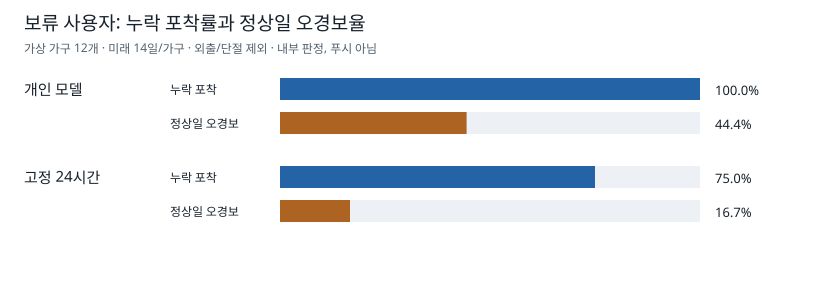

In [4]:
from html import escape
from IPython.display import SVG, display

def comparison_svg(result):
    personal = result["holdout_personal"]
    fixed = result["holdout_fixed_24h"]
    measures = [("개인 모델", personal), ("고정 24시간", fixed)]
    parts = ['<svg xmlns="http://www.w3.org/2000/svg" width="820" height="290" viewBox="0 0 820 290">',
             '<rect width="820" height="290" fill="white"/>',
             '<text x="24" y="30" font-family="sans-serif" font-size="19" fill="#17212b">보류 사용자: 누락 포착률과 정상일 오경보율</text>',
             '<text x="24" y="53" font-family="sans-serif" font-size="12" fill="#52606d">가상 가구 12개 · 미래 14일/가구 · 외출/단절 제외 · 내부 판정, 푸시 아님</text>']
    for index, (name, values) in enumerate(measures):
        y = 78 + index * 88
        parts.append(f'<text x="24" y="{y+17}" font-family="sans-serif" font-size="15" fill="#17212b">{escape(name)}</text>')
        for metric, offset, color, label in (("recall", 0, "#2463a6", "누락 포착"),
                                             ("false_positive_rate", 34, "#ad6321", "정상일 오경보")):
            value = values[metric]
            parts.extend([f'<text x="170" y="{y+offset+16}" font-family="sans-serif" font-size="12" fill="#17212b">{label}</text>',
                          f'<rect x="280" y="{y+offset}" width="420" height="22" fill="#edf1f5"/>',
                          f'<rect x="280" y="{y+offset}" width="{420*value:.1f}" height="22" fill="{color}"/>',
                          f'<text x="715" y="{y+offset+17}" font-family="sans-serif" font-size="13" fill="#17212b">{value*100:.1f}%</text>'])
    parts.append('</svg>')
    return ''.join(parts)

display(SVG(comparison_svg(result)))


## 해석

한 번의 늦은 사용이나 자연스러운 미사용도 실시간으로는 예상 창 누락과 구분하기 어렵습니다. 따라서 이 노트북의 오경보율은 내부 후보 판정의 부담을 보여주며, 실제 보호자 알림의 오경보율과 다릅니다. 불규칙 간격은 과거 간격 95백분위+2시간 경로로, 며칠간 감소는 장기 비교 경로로 별도 확인합니다. 이 두 결과도 가상 기능 점검일 뿐입니다. 실제 관측이 쌓이면 현재 모델과 고정 기준을 같은 기간에 다시 비교해야 합니다.


## 4. 검토용 후보 내보내기

아래 셀은 JSON 파일을 현재 Colab 세션에 저장합니다. Home Assistant 설정이나 실행 중인 모델을 바꾸지 않습니다.


In [5]:
import json

candidate = {
    "schema_version": 1,
    "status": "offline_candidate_only",
    "model": "personal_usage_v1",
    "alert_probability": result["selected_threshold"],
    "train_seeds": result["train_seeds"],
    "holdout_seeds": result["holdout_seeds"],
    "holdout_personal": result["holdout_personal"],
    "warning": "Synthetic behavior only. Review real observations before changing live alerts.",
}
with open("personal_usage_candidate.json", "w", encoding="utf-8") as handle:
    json.dump(candidate, handle, ensure_ascii=False, indent=2)
print("검토용 후보 저장: personal_usage_candidate.json")


검토용 후보 저장: personal_usage_candidate.json
